In [22]:
import pandas as pd 
import plotly.express as px
import fastf1
import fastf1.plotting
fastf1.plotting.setup_mpl(color_scheme='fastf1')
driver_colors = fastf1.plotting.get_driver_color_mapping(session=race)
compound_colors = fastf1.plotting.get_compound_mapping(session=race)

req            INFO 	Using cached data for driver_info


In [2]:
race = fastf1.get_session(2026, 'United States Grand Prix', 'R')
race.load()

req         WARNING 	DEFAULT CACHE ENABLED! (485.58 MB) /Users/jakesherman/Library/Caches/fastf1
events      WARNING 	Correcting user input 'United States Grand Prix' to 'United States Grand Prix'
core           INFO 	Loading data for United States Grand Prix - Race [v3.9.2]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
core        WARNING 	Fixed incorrect tyre stint information for driver '18'
core        WARNING 	Driver 12 completed the race distance 00:00.039000 before the recorded end of the session.
req            INFO 	Using cached data for car_data
req            INFO 	Usin

In [3]:
top_5 = race.results.sort_values('Position').head(5)['Abbreviation'].tolist()
print(top_5)

['ANT', 'LEC', 'VER', 'HAM', 'NOR']


In [14]:
laps = race.laps.pick_drivers(top_5).pick_quicklaps()[['Driver', 'LapNumber', 'LapTime']].copy()
laps['LapTimeSeconds'] = laps['LapTime'].dt.total_seconds()
lapsdf = pd.DataFrame(laps.dropna(subset=['LapTimeSeconds']))

In [15]:
lapsdf

,Driver,LapNumber,LapTime,LapTimeSeconds
2,NOR,3.0,0 days 00:01:41.694000,101.694
3,NOR,4.0,0 days 00:01:41.346000,101.346
4,NOR,5.0,0 days 00:01:41.442000,101.442
5,NOR,6.0,0 days 00:01:41.788000,101.788
6,NOR,7.0,0 days 00:01:42.037000,102.037
...,...,...,...,...
805,HAM,49.0,0 days 00:01:38.756000,98.756
806,HAM,50.0,0 days 00:01:39.147000,99.147
810,HAM,54.0,0 days 00:01:38.629000,98.629
811,HAM,55.0,0 days 00:01:38.535000,98.535


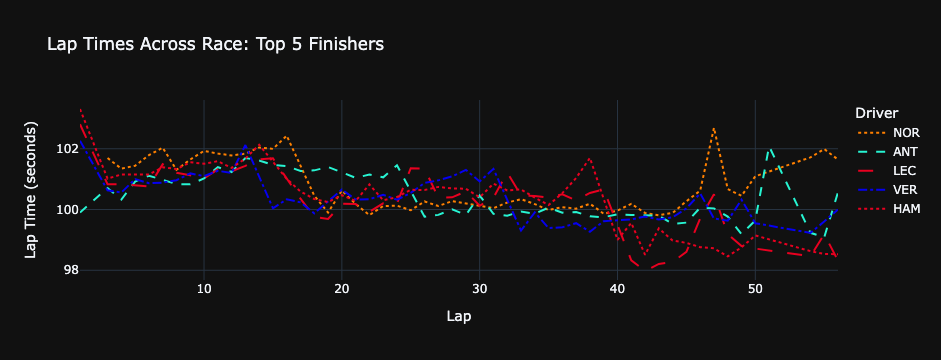

In [69]:
dash_map = {'HAM': 'dot'}

fig1 = px.line(
    lapsdf,
    x='LapNumber',
    y='LapTimeSeconds',
    color='Driver',
    line_dash='Driver',
    line_dash_map=dash_map,
    color_discrete_map=driver_colors,
    title='Lap Times Across Race: Top 5 Finishers',
    labels={'LapNumber': 'Lap', 'LapTimeSeconds': 'Lap Time (seconds)'},
    template='plotly_dark'
)
fig1.show()

In [17]:
compounds = race.laps[['Driver', 'LapNumber', 'Compound']]
lapsdf = lapsdf.merge(compounds, on=['Driver', 'LapNumber'], how='left')

In [18]:
lapsdf

,Driver,LapNumber,LapTime,LapTimeSeconds,Compound
0,NOR,3.0,0 days 00:01:41.694000,101.694,MEDIUM
1,NOR,4.0,0 days 00:01:41.346000,101.346,MEDIUM
2,NOR,5.0,0 days 00:01:41.442000,101.442,MEDIUM
3,NOR,6.0,0 days 00:01:41.788000,101.788,MEDIUM
4,NOR,7.0,0 days 00:01:42.037000,102.037,MEDIUM
...,...,...,...,...,...
247,HAM,49.0,0 days 00:01:38.756000,98.756,HARD
248,HAM,50.0,0 days 00:01:39.147000,99.147,HARD
249,HAM,54.0,0 days 00:01:38.629000,98.629,HARD
250,HAM,55.0,0 days 00:01:38.535000,98.535,HARD


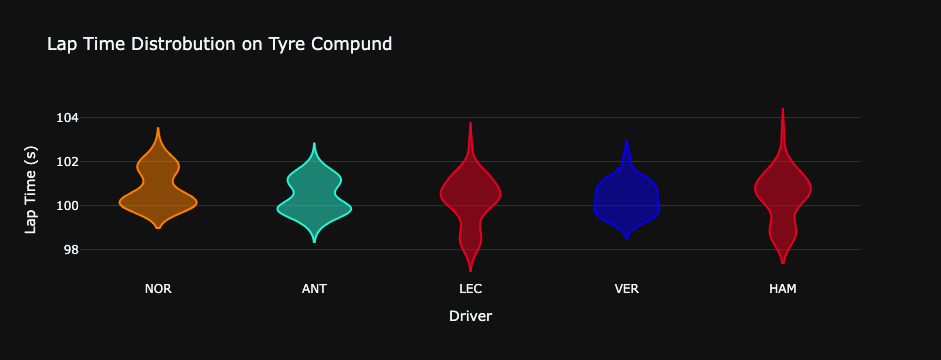

In [27]:
violin = px.violin(
    lapsdf,
    x='Driver',
    y='LapTimeSeconds',
    color='Driver',
    color_discrete_map=driver_colors,
    points=False,
    violinmode='overlay',
    title='Lap Time Distrobution on Tyre Compund',
    labels={'LapTimeSeconds': 'Lap Time (s)', 'Driver': 'Driver'},
    template='plotly_dark'
)
violin.update_traces(showlegend=False)

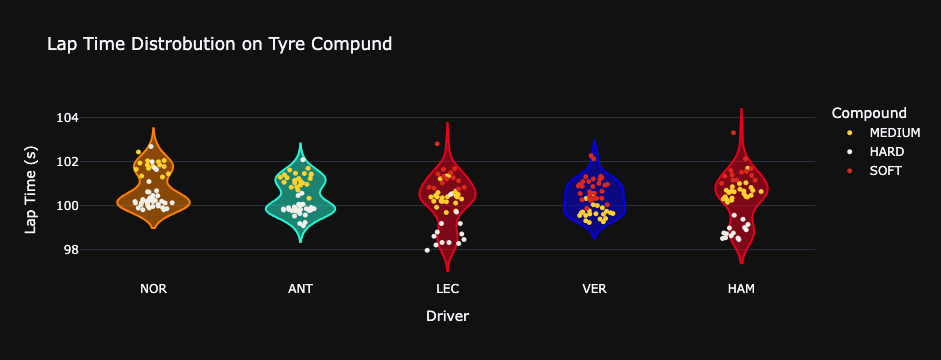

In [28]:
dots = px.strip(
    lapsdf,
    x='Driver',
    y='LapTimeSeconds',
    color='Compound',
    stripmode='overlay',
    color_discrete_map=compound_colors,
    template = 'plotly_dark'
)
dots.update_traces(jitter=0.6, marker_size=5)

violin.add_traces(dots.data)
violin.update_layout(boxmode='overlay', legend_title_text='Compound')
violin.show()

In [40]:
rows = []
for driver in top_5:
    driver_laps = race.laps.pick_drivers(driver).pick_quicklaps()
    
    for _, lap in driver_laps.iterlaps():
        rows.append({
            'Driver': driver,
            'LapNumber': lap['LapNumber'],
            'AvgSpeed': lap.get_car_data()['Speed'].mean()
        })

In [42]:
speeddf = pd.DataFrame(rows)

In [43]:
speeddf


,Driver,LapNumber,AvgSpeed
0,ANT,1.0,184.659574
1,ANT,3.0,194.697613
2,ANT,4.0,193.906593
3,ANT,5.0,193.437333
4,ANT,6.0,191.372283
...,...,...,...
248,NOR,49.0,194.613514
249,NOR,50.0,194.654450
250,NOR,54.0,193.920635
251,NOR,55.0,190.877660


In [45]:
lapsdf = lapsdf.merge(speeddf, on=['Driver', 'LapNumber'], how='left')

In [46]:
lapsdf

,Driver,LapNumber,LapTime,LapTimeSeconds,Compound,AvgSpeed
0,NOR,3.0,0 days 00:01:41.694000,101.694,MEDIUM,190.188329
1,NOR,4.0,0 days 00:01:41.346000,101.346,MEDIUM,193.046196
2,NOR,5.0,0 days 00:01:41.442000,101.442,MEDIUM,190.502660
3,NOR,6.0,0 days 00:01:41.788000,101.788,MEDIUM,194.770270
4,NOR,7.0,0 days 00:01:42.037000,102.037,MEDIUM,190.691710
...,...,...,...,...,...,...
247,HAM,49.0,0 days 00:01:38.756000,98.756,HARD,200.060440
248,HAM,50.0,0 days 00:01:39.147000,99.147,HARD,198.791444
249,HAM,54.0,0 days 00:01:38.629000,98.629,HARD,198.591281
250,HAM,55.0,0 days 00:01:38.535000,98.535,HARD,198.865014


In [48]:
heat_data = lapsdf.pivot(index='Driver', columns='LapNumber', values='AvgSpeed')
heat_data = heat_data.reindex(top_5)

In [1]:
# change this to the positions graph for analysis
heatspeed = px.imshow(
    heat_data,
    text_auto='.0f',
    aspect='auto',
    color_continuous_scale='RdYlGn',
    template='plotly_dark',
    title='Average Speeds by Top 5 in the Race',
    labels={'x': 'Lap #', 'y': 'Driver', 'color': 'Avg Speed'}
)
heatspeed.show()

NameError: name 'px' is not defined

In [72]:
stints = (
    pd.DataFrame(race.laps.pick_drivers(top_5))
    .groupby(['Driver', 'Stint', 'Compound'], as_index=False)
    .agg(StartLap=('LapNumber', 'min'), EndLap=('LapNumber', 'max'))
)
stints['StintLength'] = stints['EndLap'] - stints['StartLap'] + 1
stints['BarStart'] = stints['StartLap'] - 1

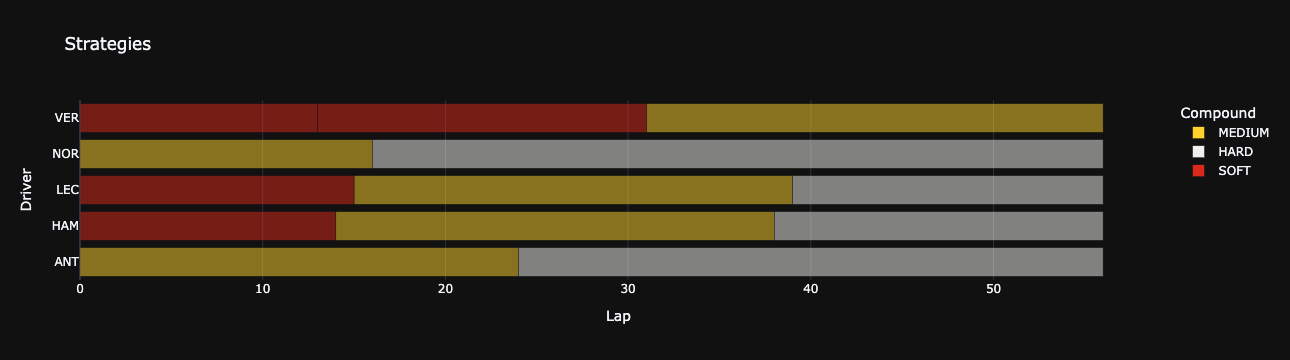

In [76]:
strat = px.bar(
    stints,
    x='StintLength',
    y='Driver',
    base='BarStart',
    orientation='h',
    color='Compound',
    barmode='overlay',
    color_discrete_map=compound_colors,
    template='plotly_dark',
    title='Strategies',
    labels={'StintLength': 'Lap'},
    hover_data=['StartLap', 'EndLap']
)
strat.show()

In [99]:
ham_lap = race.laps.pick_drivers('HAM').pick_fastest()

In [100]:
ham_lap = ham_lap.get_car_data().add_distance()

In [101]:
ham_lap

,Date,RPM,Speed,nGear,Throttle,Brake,DRS,Source,Time,SessionTime,Distance
0,2026-10-25 21:23:26.565,11239.0,229.0,5,99.0,False,0,car,0 days 00:00:00.031000,0 days 02:16:31.598000,1.971944
1,2026-10-25 21:23:26.845,10758.0,235.0,6,99.0,False,0,car,0 days 00:00:00.311000,0 days 02:16:31.878000,20.249722
2,2026-10-25 21:23:27.245,11306.0,247.0,6,99.0,False,0,car,0 days 00:00:00.711000,0 days 02:16:32.278000,47.694167
3,2026-10-25 21:23:27.445,11491.0,254.0,6,99.0,False,0,car,0 days 00:00:00.911000,0 days 02:16:32.478000,61.805278
4,2026-10-25 21:23:27.844,10457.0,263.0,6,99.0,False,0,car,0 days 00:00:01.310000,0 days 02:16:32.877000,90.954444
...,...,...,...,...,...,...,...,...,...,...,...
359,2026-10-25 21:25:03.965,11727.0,189.0,4,99.0,False,0,car,0 days 00:01:37.431000,0 days 02:18:08.998000,5396.646389
360,2026-10-25 21:25:04.125,11062.0,193.0,4,99.0,False,0,car,0 days 00:01:37.591000,0 days 02:18:09.158000,5405.224167
361,2026-10-25 21:25:04.445,10824.0,204.0,5,99.0,False,0,car,0 days 00:01:37.911000,0 days 02:18:09.478000,5423.357500
362,2026-10-25 21:25:04.725,11425.0,216.0,5,99.0,False,0,car,0 days 00:01:38.191000,0 days 02:18:09.758000,5440.157500
